In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
# Set max column width to None to display the absolute full text
pd.set_option('display.max_colwidth', None)

In [25]:
df = pd.read_csv('airline_tweets.csv')
df.head()

,text,airline_sentiment,airline
0,@VirginAmerica What @dhepburn said.,neutral,Virgin America
1,@VirginAmerica plus you've added commercials to the experience... tacky.,positive,Virgin America
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,neutral,Virgin America
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",negative,Virgin America
4,@VirginAmerica and it's a really big bad thing about it,negative,Virgin America


In [26]:
df.shape

(14640, 3)

In [27]:
df.columns

Index(['text                                                                                                                                                                                        ',
       ' airline_sentiment', ' airline'],
      dtype='object')

In [28]:
df.columns = df.columns.str.strip()

In [29]:
df.columns

Index(['text', 'airline_sentiment', 'airline'], dtype='object')

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   text               14640 non-null  object
 1   airline_sentiment  14640 non-null  object
 2   airline            14640 non-null  object
dtypes: object(3)
memory usage: 343.3+ KB


In [31]:
df.describe()

,text,airline_sentiment,airline
count,14640,14640,14640
unique,14427,3,6
top,@united thanks,negative,United
freq,6,9178,3822


In [32]:
df['airline'].value_counts()

airline
United            3822
US Airways        2913
American          2759
Southwest         2420
Delta             2222
Virgin America     504
Name: count, dtype: int64

In [33]:
df['airline_sentiment'].value_counts()

airline_sentiment
negative             9178
neutral              3099
positive             2363
Name: count, dtype: int64

In [34]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [35]:
analyzer = SentimentIntensityAnalyzer()

In [36]:
def get_sentiment(text):
    score = analyzer.polarity_scores(str(text))['compound']

    if score >= 0.05:
        return 'positive'
    
    elif score <= -0.05:
        return 'negative'
    
    else:
        return 'neutral'
    

In [37]:
df['vader_sentiment'] = df['text'].apply(get_sentiment)

In [38]:
df[['text', 'vader_sentiment']].head()

,text,vader_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials to the experience... tacky.,neutral
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,neutral
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",negative
4,@VirginAmerica and it's a really big bad thing about it,negative


In [39]:
df['vader_sentiment'].value_counts()

vader_sentiment
positive    7615
negative    4464
neutral     2561
Name: count, dtype: int64

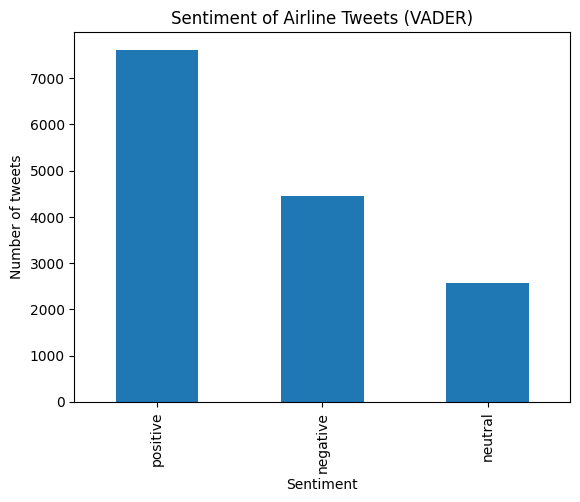

In [40]:
df['vader_sentiment'].value_counts().plot(kind='bar')
plt.title('Sentiment of Airline Tweets (VADER)')
plt.xlabel('Sentiment'); plt.ylabel('Number of tweets')
plt.show()

In [41]:
df[['text', 'airline_sentiment', 'vader_sentiment']].head(20)


,text,airline_sentiment,vader_sentiment
0,@VirginAmerica What @dhepburn said.,neutral,neutral
1,@VirginAmerica plus you've added commercials to the experience... tacky.,positive,neutral
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,neutral,neutral
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they have little recourse",negative,negative
4,@VirginAmerica and it's a really big bad thing about it,negative,negative
5,@VirginAmerica seriously would pay $30 a flight for seats that didn't have this playing.\nit's really the only bad thing about flying VA,negative,negative
6,"@VirginAmerica yes, nearly every time I fly VX this “ear worm” won’t go away :)",positive,positive
7,"@VirginAmerica Really missed a prime opportunity for Men Without Hats parody, there. https://t.co/mWpG7grEZP",neutral,positive
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",positive,positive
9,"@VirginAmerica it was amazing, and arrived an hour early. You're too good to me.",positive,positive


In [42]:
# tweets where VADER and the humans disagree
mismatch = df[df['vader_sentiment'] != df['airline_sentiment']]
mismatch[['text', 'airline_sentiment', 'vader_sentiment']].sample(10)

,text,airline_sentiment,vader_sentiment
59,@VirginAmerica New marketing song? https://t.co/F2LFULCbQ7 let us know what you think?,neutral,neutral
8547,".@JetBlue thx for confirming! Again, yr team is awesome. Thanks for the prompt &amp; helpful response! Cheers to less snow in everyone's future",positive,positive
3321,@united thanks for making sure they hear the message!,positive,positive
4061,"@united thanks for a terrible experience at EWR. Customers should be treated as a priority, not as an inconvenience #tryagain",negative,positive
6279,@SouthwestAir @love_dragonss holy fuckinf shit,positive,negative
12162,@AmericanAir I thought all those planes were retired? #MD80,neutral,neutral
13745,@AmericanAir We have been sitting on this bird #AA1457 for 2 hrs on the dfw tarmac. Some water would be nice. Where's your manners?,negative,positive
1,@VirginAmerica plus you've added commercials to the experience... tacky.,positive,neutral
6078,@SouthwestAir love bridesmaid dancing Can't wait for you to fly into puerto Vallarta and kick united ass!,positive,positive
10545,@USAirways providing poor customer service by responding to complaints with a copy and paste tempLate Flight unreLate Flightd to complaint #usairwaysfail,negative,negative


In [43]:
print(mismatch.loc[1293, 'text'])

@united funny I paid to check my bag and now flight 1086 is BEGGING folks to check bags for free 1 hour before flight. #notcool                                                             


In [20]:
## Vader's Counts : 
# positive    7615
# negative    4464
# neutral     2561


## Human Label Counts :
# positive     2363
# negative     9178
# neutral      3099

In [21]:
## Sentiment over-predicted by Vader : Positive